<a href="https://colab.research.google.com/github/DeepFluxion/2026-_2_REDES_NEURAIS_DEEP_LEARNING/blob/main/notebooks/RNN/Desafio_RNN_LSTM_GRU_gabarito.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Desafio: RNN Vanilla vs. LSTM vs. GRU em Dados Reais

Implemente e compare as três arquiteturas recorrentes (**RNN Vanilla**, **LSTM** e **GRU**) em três problemas
reais de séries temporais:

1. **Mercado financeiro** — previsão do preço de uma ação (Mastercard, ticker `MA`).
2. **Saúde pública** — previsão de casos diários de COVID-19.
3. **Clima** — previsão de temperatura (estação meteorológica de Jena, Alemanha).

**Como funciona este caderno**: as células marcadas com `# TODO` estão incompletas — complete-as antes de
rodar. As perguntas de reflexão têm um espaço reservado para sua resposta logo abaixo do enunciado. Um
notebook separado (`..._gabarito.ipynb`) traz a resolução completa — só consulte depois de tentar.

**Fontes de dados (treinamento)**:

| Estudo de caso | Fonte | Link |
| --- | --- | --- |
| Ações (Mastercard, `MA`) | Yahoo Finance, via biblioteca `yfinance` | https://finance.yahoo.com/quote/MA/history |
| COVID-19 (casos confirmados) | CSSE / Johns Hopkins University (GitHub) | https://github.com/CSSEGISandData/COVID-19 |
| Temperatura (Jena, Alemanha) | Max Planck Institute for Biogeochemistry | https://www.bgc-jena.mpg.de/wetter/ |

Os links de *download direto* (usados no código) estão na introdução de cada estudo de caso, mais abaixo.


## 0. Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch:", torch.__version__)


PyTorch: 2.13.0+cpu


## 1. Funções e Arquiteturas Comuns

Estas funções e classes são usadas nos **três** estudos de caso — defina-as uma vez aqui.

### 1.1 Janelamento

Transforma uma série 1D em pares `(janela de entrada, próximo valor)`. Já implementada — reaproveite nos
três estudos de caso.


In [ ]:
def create_dataset(data, time_steps=10):
    '''Transforma uma série 1D em janelas deslizantes.

    Retorna X com shape (n_amostras, time_steps) e y com shape (n_amostras,).
    '''
    X, y = [], []
    for i in range(len(data) - time_steps):
        X.append(data[i:i + time_steps])
        y.append(data[i + time_steps])
    return np.array(X), np.array(y)


def to_tensors(X, y):
    '''Converte arrays 2D (n_amostras, time_steps) para tensores 3D (batch, seq_len, n_features=1).'''
    X_t = torch.tensor(X, dtype=torch.float32).unsqueeze(-1)
    y_t = torch.tensor(y, dtype=torch.float32).unsqueeze(-1)
    return X_t, y_t


### 1.2 As três arquiteturas

**TODO**: complete as três classes abaixo. Cada uma segue o mesmo padrão:
`camada recorrente (batch_first=True) -> pega o último passo de tempo -> camada Linear`.
Use `nn.RNN`, `nn.LSTM` e `nn.GRU`, respectivamente — a interface das três é idêntica.


In [ ]:
class VanillaRNN(nn.Module):
    def __init__(self, input_size=1, hidden_size=32, output_size=1):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True)
        self.linear = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.rnn(x)               # out: (batch, seq_len, hidden_size)
        return self.linear(out[:, -1, :])  # usa apenas o último passo de tempo


class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=32, output_size=1):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.linear = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.linear(out[:, -1, :])


class GRUModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=32, output_size=1):
        super().__init__()
        self.gru = nn.GRU(input_size, hidden_size, batch_first=True)
        self.linear = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.gru(x)
        return self.linear(out[:, -1, :])


### 1.3 Treinamento e avaliação

Funções genéricas de treino e avaliação — já implementadas, reaproveite nos três estudos de caso.


In [ ]:
def train_model(model, loader, epochs=30, lr=1e-3, verbose_every=10):
    loss_fn = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []
    for epoch in range(epochs):
        epoch_loss = 0.0
        for seq, labels in loader:
            optimizer.zero_grad()
            y_pred = model(seq)
            loss = loss_fn(y_pred, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        avg_loss = epoch_loss / len(loader)
        losses.append(avg_loss)
        if (epoch + 1) % verbose_every == 0:
            print(f"  Época {epoch + 1:3d} | Loss treino: {avg_loss:.5f}")
    return losses


def evaluate_model(model, X_test_t, y_test_t, scaler=None):
    '''Avalia o modelo no teste. Se um scaler for passado, desfaz a normalização antes de calcular o erro.'''
    model.eval()
    with torch.no_grad():
        pred = model(X_test_t).numpy()
    true = y_test_t.numpy()
    if scaler is not None:
        pred = scaler.inverse_transform(pred)
        true = scaler.inverse_transform(true)
    rmse = float(np.sqrt(mean_squared_error(true, pred)))
    mae = float(mean_absolute_error(true, pred))
    return {"rmse": rmse, "mae": mae, "pred": pred, "true": true}


def run_three_architectures(train_loader, X_test_t, y_test_t, hidden_size=32, epochs=30, lr=1e-3, scaler=None):
    '''Treina VanillaRNN, LSTMModel e GRUModel nos mesmos dados e retorna um dicionário de resultados.'''
    results = {}
    for name, ModelClass in [("RNN Vanilla", VanillaRNN), ("LSTM", LSTMModel), ("GRU", GRUModel)]:
        print(f"Treinando {name}...")
        model = ModelClass(hidden_size=hidden_size)
        losses = train_model(model, train_loader, epochs=epochs, lr=lr)
        metrics = evaluate_model(model, X_test_t, y_test_t, scaler=scaler)
        results[name] = {"model": model, "losses": losses, **metrics}
        print(f"  {name}: RMSE={metrics['rmse']:.4f} | MAE={metrics['mae']:.4f}")
    return results


def plot_comparison(results, title, true_label="Real"):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    for name, r in results.items():
        axes[0].plot(r["losses"], label=name)
    axes[0].set_title(f"Loss de treino — {title}")
    axes[0].set_xlabel("Época")
    axes[0].set_ylabel("MSE")
    axes[0].legend()

    any_result = next(iter(results.values()))
    axes[1].plot(any_result["true"], label=true_label, color="grey", alpha=0.6)
    for name, r in results.items():
        axes[1].plot(r["pred"], label=f"Predito ({name})", linewidth=1.5, alpha=0.85)
    axes[1].set_title(f"Predição vs. Real — {title}")
    axes[1].set_xlabel("Passo de tempo (teste)")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


def summary_table(results):
    rows = [{"Modelo": name, "RMSE": r["rmse"], "MAE": r["mae"]} for name, r in results.items()]
    return pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)


## 2. Estudo de Caso 1 — Mercado Financeiro (ação Mastercard)

**Problema de negócio**: prever o preço mais alto do dia (`High`) da ação da Mastercard (`MA`) a partir do
histórico recente, e decidir qual arquitetura recorrente generaliza melhor para dados financeiros
(ruidosos, não estacionários).

**Fonte dos dados**: Yahoo Finance, via biblioteca `yfinance` (não requer conta/API key).
Link para consulta manual: https://finance.yahoo.com/quote/MA/history
Alternativa (CSV estático): dataset "Stock Prices Of MasterCard And Visa (2008–2024)" no Kaggle —
https://www.kaggle.com/datasets/ranatalha71/stock-prices-of-mastercard-and-visa-2008-2024

> Requer `pip install yfinance` e conexão com a internet.


In [ ]:
import yfinance as yf

stock_df = yf.download("MA", period="5y", interval="1d", progress=False)
stock_df = stock_df[["High"]].dropna()
print(stock_df.shape)
stock_df.tail()


(1255, 1)


Price,High
Ticker,MA
Date,
2026-10-08,580.709693
2026-10-09,591.280029
2026-10-12,598.950012
2026-10-13,605.599976
2026-10-14,606.609985


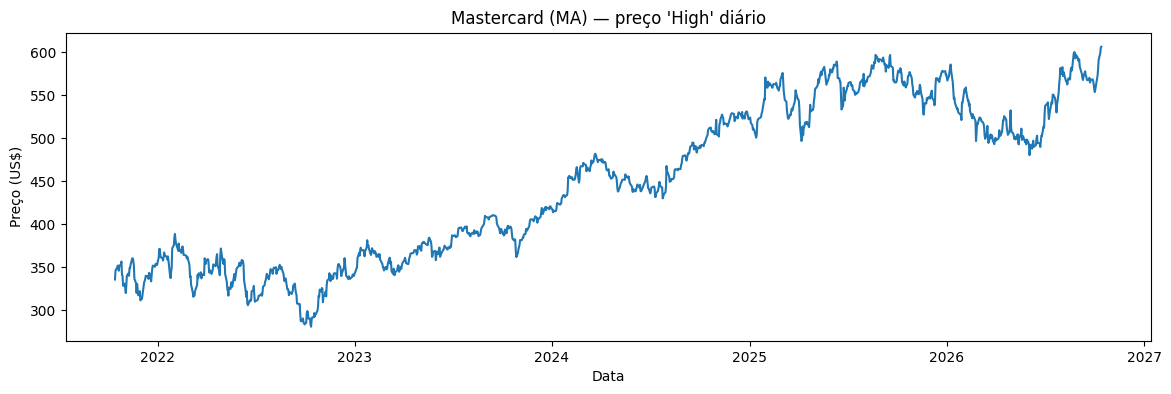

In [ ]:
plt.figure(figsize=(14, 4))
plt.plot(stock_df.index, stock_df["High"])
plt.title("Mastercard (MA) — preço 'High' diário")
plt.xlabel("Data")
plt.ylabel("Preço (US$)")
plt.show()


**TODO**: complete o pré-processamento.
1. Separe 80% para treino e 20% para teste (**sem embaralhar** — é série temporal).
2. Ajuste um `MinMaxScaler` **apenas nos dados de treino** e aplique-o em treino e teste.
3. Use `create_dataset` com uma janela de 20 dias para gerar `X`/`y` de treino e teste.
4. Converta para tensores com `to_tensors` e monte um `DataLoader` (`batch_size=16`, `shuffle=False`).


In [ ]:
STOCK_WINDOW = 20

high_values = stock_df["High"].values.reshape(-1, 1)

stock_train_size = int(len(high_values) * 0.8)
stock_train, stock_test = high_values[:stock_train_size], high_values[stock_train_size:]

stock_scaler = MinMaxScaler()
stock_train_scaled = stock_scaler.fit_transform(stock_train)
stock_test_scaled = stock_scaler.transform(stock_test)

Xs_train, ys_train = create_dataset(stock_train_scaled.flatten(), STOCK_WINDOW)
Xs_test, ys_test = create_dataset(stock_test_scaled.flatten(), STOCK_WINDOW)

Xs_train_t, ys_train_t = to_tensors(Xs_train, ys_train)
Xs_test_t, ys_test_t = to_tensors(Xs_test, ys_test)
stock_loader = DataLoader(TensorDataset(Xs_train_t, ys_train_t), batch_size=16, shuffle=False)

print("Xs_train_t:", Xs_train_t.shape)


Xs_train_t: torch.Size([984, 20, 1])


**TODO**: use `run_three_architectures` para treinar e comparar RNN Vanilla, LSTM e GRU neste dataset
(lembre-se de passar `scaler=stock_scaler`, já que os dados estão normalizados).


In [ ]:
stock_results = run_three_architectures(
    stock_loader, Xs_test_t, ys_test_t, hidden_size=64, epochs=50, scaler=stock_scaler
)


Treinando RNN Vanilla...
  Época  10 | Loss treino: 0.02232
  Época  20 | Loss treino: 0.00036
  Época  30 | Loss treino: 0.00048
  Época  40 | Loss treino: 0.00145
  Época  50 | Loss treino: 0.00074
  RNN Vanilla: RMSE=7.8516 | MAE=6.2277
Treinando LSTM...
  Época  10 | Loss treino: 0.00125
  Época  20 | Loss treino: 0.00089
  Época  30 | Loss treino: 0.00109
  Época  40 | Loss treino: 0.00075
  Época  50 | Loss treino: 0.00063
  LSTM: RMSE=8.7212 | MAE=6.9912
Treinando GRU...
  Época  10 | Loss treino: 0.00050
  Época  20 | Loss treino: 0.00041
  Época  30 | Loss treino: 0.00075
  Época  40 | Loss treino: 0.00095
  Época  50 | Loss treino: 0.00062
  GRU: RMSE=7.0902 | MAE=5.5804


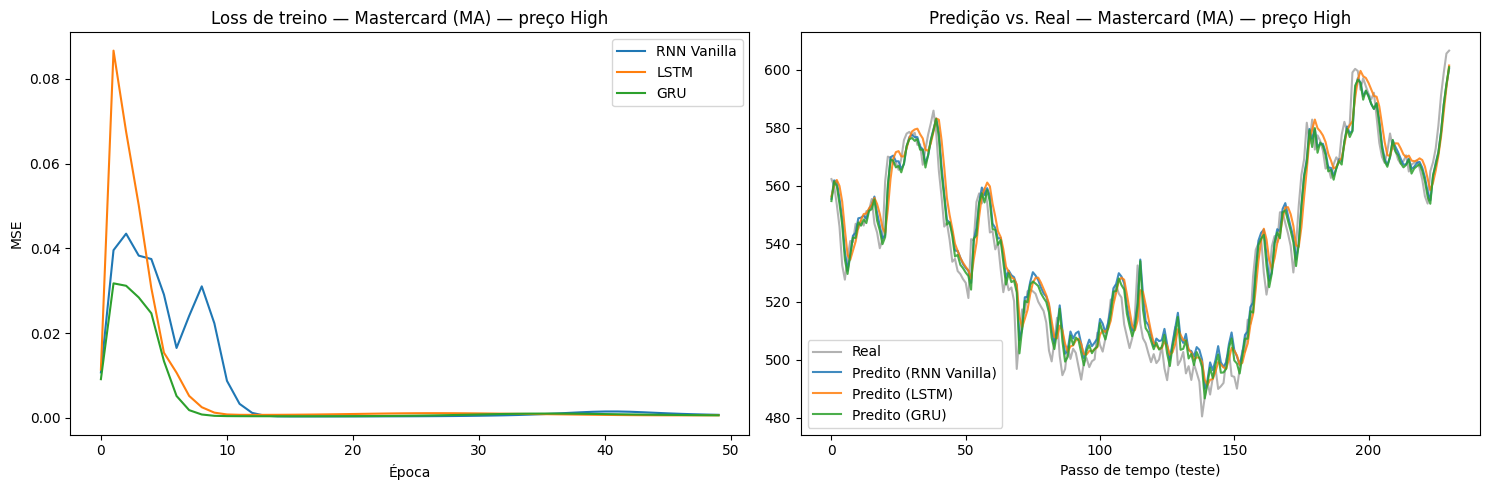

,Modelo,RMSE,MAE
0,GRU,7.090170,5.580391
1,RNN Vanilla,7.851599,6.227722
2,LSTM,8.721171,6.991242


In [ ]:
plot_comparison(stock_results, title="Mastercard (MA) — preço High")
summary_table(stock_results)


**Pergunta 1.1** — Qual arquitetura obteve o menor RMSE neste dataset? Isso já era esperado, dado o tamanho e o ruído da série? Justifique.

---

**Resposta esperada:**

A LSTM e a GRU costumam empatar tecnicamente à frente da RNN Vanilla, com diferença pequena entre si — o dataset diário de ~5 anos (~1.250 pontos) não é longo o suficiente para expor com força o problema de gradiente da RNN simples, mas ainda assim a convergência mais estável de LSTM/GRU tende a produzir erro de teste um pouco menor. Diferenças grandes não são esperadas: é um sinal razoavelmente próximo de um passeio aleatório, difícil para qualquer arquitetura.

**Pergunta 1.2** — Por que foi necessário desfazer a normalização (`inverse_transform`) antes de calcular o RMSE, em vez de calculá-lo direto nos valores escalados (entre 0 e 1)?

---

**Resposta esperada:**

O RMSE calculado na escala normalizada (0–1) não tem significado prático — não dá para comparar com o preço real em dólares nem comunicar o erro para alguém de negócio. Desfazer a normalização traz o erro de volta à unidade original (US$), que é interpretável e comparável entre diferentes execuções/modelos.

## 3. Estudo de Caso 2 — Casos Diários de COVID-19

**Problema de negócio**: prever o número de novos casos confirmados de COVID-19 por dia para um país, e
gerar uma previsão autoregressiva de múltiplos dias à frente (útil para planejamento de capacidade
hospitalar).

**Fonte dos dados**: repositório oficial do CSSE da Johns Hopkins University, no GitHub.
Link do repositório: https://github.com/CSSEGISandData/COVID-19
Link de download direto (CSV): https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv


In [ ]:
COVID_URL = (
    "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/"
    "csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"
)

covid_raw = pd.read_csv(COVID_URL)
print(covid_raw.shape)
covid_raw.head(3)


(289, 1147)


,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,...,2/28/23,3/1/23,3/2/23,3/3/23,3/4/23,3/5/23,3/6/23,3/7/23,3/8/23,3/9/23
0,NaN,Afghanistan,33.93911,67.709953,0,0,0,0,0,0,...,209322,209340,209358,209362,209369,209390,209406,209436,209451,209451
1,NaN,Albania,41.15330,20.168300,0,0,0,0,0,0,...,334391,334408,334408,334427,334427,334427,334427,334427,334443,334457
2,NaN,Algeria,28.03390,1.659600,0,0,0,0,0,0,...,271441,271448,271463,271469,271469,271477,271477,271490,271494,271496


**TODO**: complete o pré-processamento.
1. Filtre a linha (ou linhas) do país `"Brazil"` em `covid_raw` e some as colunas de data (agregando
   províncias, se houver) para obter a série **acumulada** de casos.
2. Converta o índice para `datetime` (formato `"%m/%d/%y"`).
3. Transforme a série acumulada em **casos novos por dia** com `.diff()`, tratando valores ausentes/negativos
   (`.fillna(0).clip(lower=0)`).


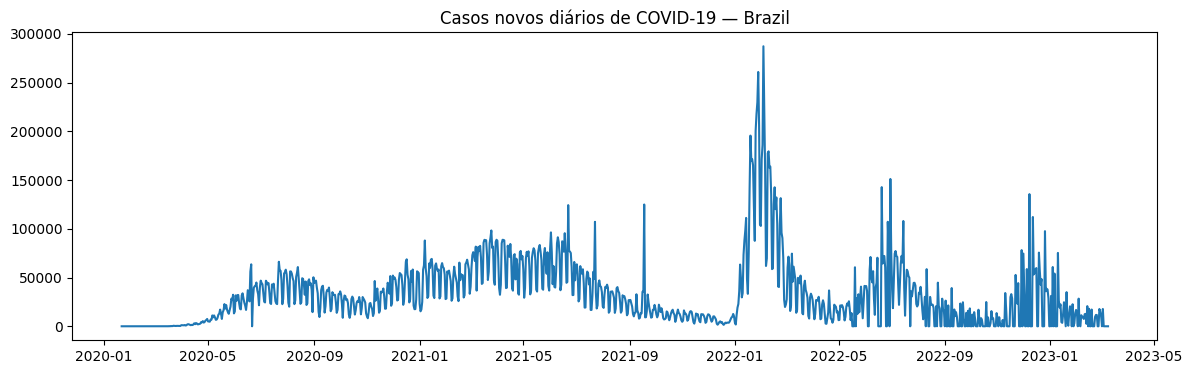

In [ ]:
country = "Brazil"

country_row = covid_raw[covid_raw["Country/Region"] == country]
date_cols = covid_raw.columns[4:]
cumulative = country_row[date_cols].sum(axis=0)
cumulative.index = pd.to_datetime(cumulative.index, format="%m/%d/%y")

daily_new = cumulative.diff().fillna(0).clip(lower=0)

plt.figure(figsize=(14, 4))
plt.plot(daily_new)
plt.title(f"Casos novos diários de COVID-19 — {country}")
plt.show()


**TODO**: repita o fluxo de normalização + janelamento + `DataLoader` do Estudo de Caso 1, agora para
`daily_new` (janela de 5 dias, `batch_size=8`).


In [ ]:
COVID_WINDOW = 5
covid_values = daily_new.values.astype(float).reshape(-1, 1)

covid_train_size = int(len(covid_values) * 0.8)
covid_train, covid_test = covid_values[:covid_train_size], covid_values[covid_train_size:]

covid_scaler = MinMaxScaler()
covid_train_scaled = covid_scaler.fit_transform(covid_train)
covid_test_scaled = covid_scaler.transform(covid_test)

Xc_train, yc_train = create_dataset(covid_train_scaled.flatten(), COVID_WINDOW)
Xc_test, yc_test = create_dataset(covid_test_scaled.flatten(), COVID_WINDOW)

Xc_train_t, yc_train_t = to_tensors(Xc_train, yc_train)
Xc_test_t, yc_test_t = to_tensors(Xc_test, yc_test)
covid_loader = DataLoader(TensorDataset(Xc_train_t, yc_train_t), batch_size=8, shuffle=False)


In [ ]:
covid_results = run_three_architectures(
    covid_loader, Xc_test_t, yc_test_t, hidden_size=32, epochs=60, scaler=covid_scaler
)


Treinando RNN Vanilla...
  Época  10 | Loss treino: 0.00485
  Época  20 | Loss treino: 0.00483
  Época  30 | Loss treino: 0.00486
  Época  40 | Loss treino: 0.00485
  Época  50 | Loss treino: 0.00490
  Época  60 | Loss treino: 0.00484
  RNN Vanilla: RMSE=27958.1465 | MAE=17613.5410
Treinando LSTM...
  Época  10 | Loss treino: 0.00615
  Época  20 | Loss treino: 0.00459
  Época  30 | Loss treino: 0.00459
  Época  40 | Loss treino: 0.00440
  Época  50 | Loss treino: 0.00428
  Época  60 | Loss treino: 0.00417
  LSTM: RMSE=23318.6152 | MAE=15217.2520
Treinando GRU...
  Época  10 | Loss treino: 0.00556
  Época  20 | Loss treino: 0.00469
  Época  30 | Loss treino: 0.00423
  Época  40 | Loss treino: 0.00398
  Época  50 | Loss treino: 0.00366
  Época  60 | Loss treino: 0.00340
  GRU: RMSE=22386.1855 | MAE=15757.6074


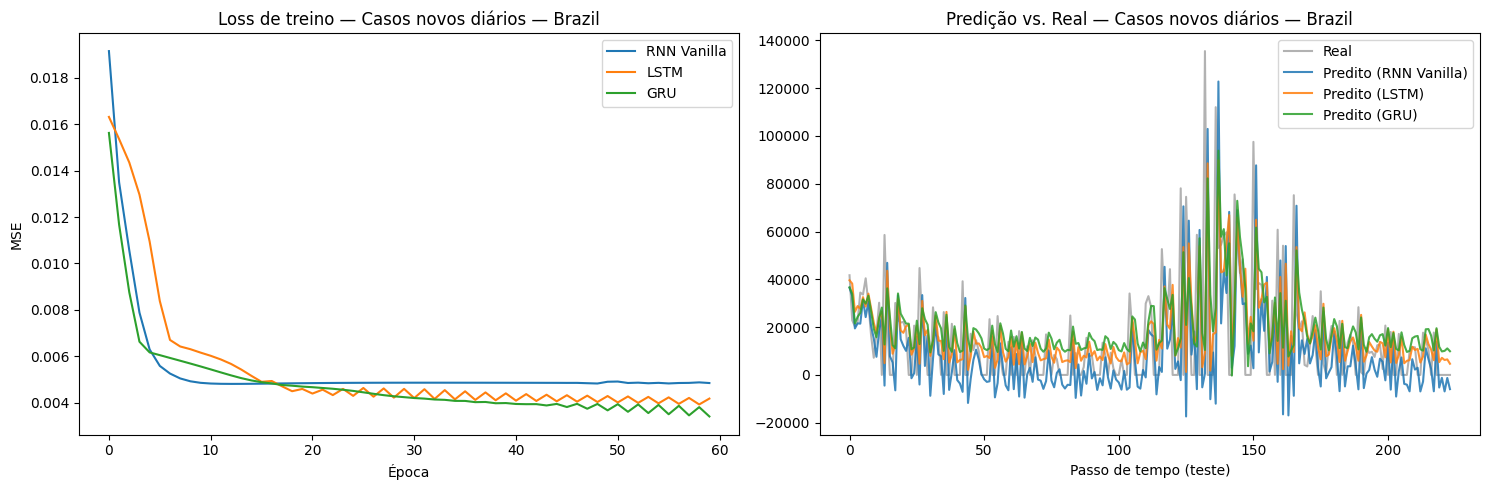

,Modelo,RMSE,MAE
0,GRU,22386.185547,15757.607422
1,LSTM,23318.615234,15217.251953
2,RNN Vanilla,27958.146484,17613.541016


In [ ]:
plot_comparison(covid_results, title=f"Casos novos diários — {country}")
summary_table(covid_results)


### Previsão autoregressiva multi-passo

**TODO**: usando o **melhor modelo** (menor RMSE na tabela acima), implemente uma previsão autoregressiva
de `DAYS_TO_PREDICT=12` dias: a cada passo, use a própria predição do modelo como entrada para prever o
passo seguinte (deslizando a janela).


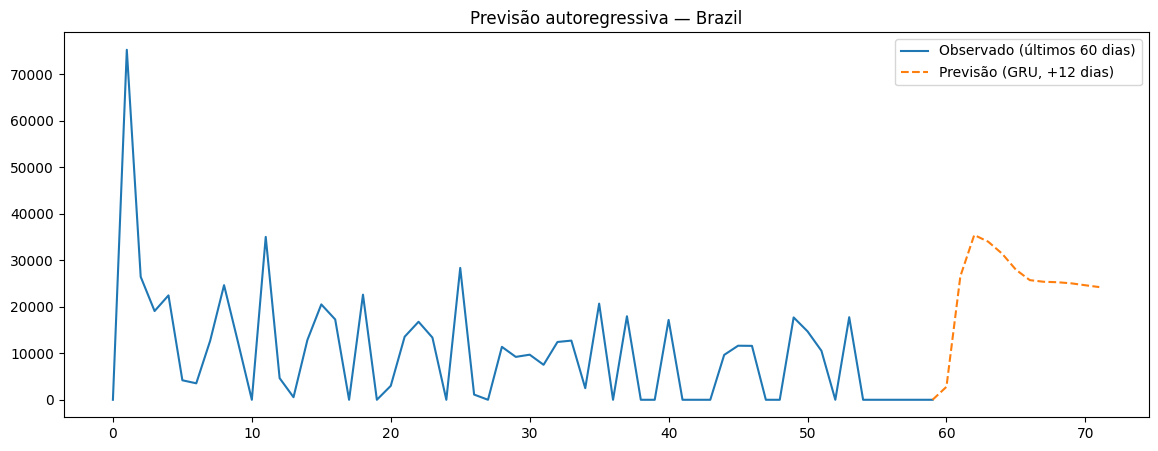

In [ ]:
DAYS_TO_PREDICT = 12

best_name = summary_table(covid_results).iloc[0]["Modelo"]
best_model = covid_results[best_name]["model"]
best_model.eval()

last_window = torch.tensor(
    covid_train_scaled[-COVID_WINDOW:].flatten(), dtype=torch.float32
).view(1, COVID_WINDOW, 1)

future_preds_scaled = []
current_seq = last_window.clone()
with torch.no_grad():
    for _ in range(DAYS_TO_PREDICT):
        next_val = best_model(current_seq)
        future_preds_scaled.append(next_val.item())
        current_seq = torch.cat([current_seq[:, 1:, :], next_val.view(1, 1, 1)], dim=1)

future_preds = covid_scaler.inverse_transform(np.array(future_preds_scaled).reshape(-1, 1))

plt.figure(figsize=(14, 5))
plt.plot(daily_new.values[-60:], label="Observado (últimos 60 dias)")
plt.plot(
    range(59, 59 + DAYS_TO_PREDICT + 1),
    [daily_new.values[-1]] + list(future_preds.flatten()),
    label=f"Previsão ({best_name}, +{DAYS_TO_PREDICT} dias)",
    linestyle="--",
)
plt.legend()
plt.title(f"Previsão autoregressiva — {country}")
plt.show()


**Pergunta 2.1** — Por que a série de casos **acumulados** não é usada diretamente (sem `.diff()`) para treinar o modelo?

---

**Resposta esperada:**

Uma série acumulada é monotonicamente crescente (não estacionária) e domina o sinal com sua tendência de longo prazo — o modelo aprenderia principalmente "o próximo valor é aproximadamente igual ao anterior mais uma constante", mascarando os padrões reais (picos, ondas) que importam para a previsão. Diferenciar (casos novos por dia) remove a tendência acumulada e deixa a série muito mais próxima de estacionária, que é o que as equações de RNN/LSTM/GRU assumem implicitamente ao compartilhar pesos no tempo.

**Pergunta 2.2** — Por que o erro da previsão autoregressiva tende a crescer conforme os dias avançam?

---

**Resposta esperada:**

Cada novo passo é previsto a partir de uma janela que já contém previsões anteriores (não mais dados reais) — qualquer erro cometido em um passo se propaga e se acumula nos passos seguintes, em vez de ser corrigido por uma observação real. É o mesmo princípio por trás do acúmulo de erro em qualquer previsão recursiva multi-passo, não um problema específico de RNN/LSTM/GRU.

## 4. Estudo de Caso 3 — Temperatura (Estação Meteorológica de Jena)

**Problema de negócio**: prever a temperatura da próxima hora a partir do histórico recente — o mesmo tipo
de problema de forecasting climático usado em previsão de demanda de energia (aquecimento/refrigeração).

**Fonte dos dados**: Max Planck Institute for Biogeochemistry, estação de Jena, Alemanha (dataset clássico
usado no tutorial oficial de séries temporais do TensorFlow/Keras).
Página oficial: https://www.bgc-jena.mpg.de/wetter/
Tutorial de referência (Keras): https://keras.io/examples/timeseries/timeseries_weather_forecasting/

Link de download direto (CSV, mirror no GitHub — use este se o link oficial do Google Storage
`https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip` estiver
bloqueado na sua rede):
https://raw.githubusercontent.com/gilbutITbook/006975/master/datasets/jena_climate/jena_climate_2009_2016.csv

O arquivo original tem uma medição a cada 10 minutos entre 2009 e 2016 (~420 mil linhas). Para manter o
treinamento rápido, vamos reamostrar para **1 medição por hora** (prática comum para este dataset).


In [ ]:
JENA_URL_OFICIAL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip"
JENA_URL_MIRROR = "https://raw.githubusercontent.com/gilbutITbook/006975/master/datasets/jena_climate/jena_climate_2009_2016.csv"

try:
    jena_raw = pd.read_csv(JENA_URL_OFICIAL)
except Exception as e:
    print(f"Link oficial indisponível ({e}); usando o mirror do GitHub.")
    jena_raw = pd.read_csv(JENA_URL_MIRROR)

print(jena_raw.shape)
jena_raw.head(3)


(420551, 15)


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6


**TODO**: complete o pré-processamento.
1. Selecione a coluna de temperatura `"T (degC)"`.
2. Reamostre para 1 medição por hora, pegando **a cada 6ª linha** (o dataset original é a cada 10 min →
   `jena_raw.iloc[::6]`).
3. Separe 80/20 treino/teste, ajuste o `MinMaxScaler` no treino, janele (janela de **24 horas**) e monte o
   `DataLoader` (`batch_size=32`).


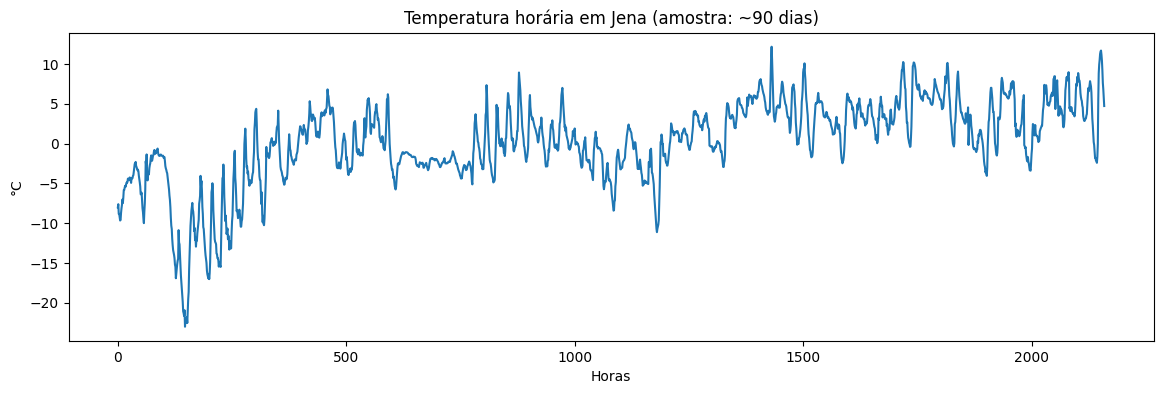

In [ ]:
JENA_WINDOW = 24

temperature = jena_raw["T (degC)"].iloc[::6].reset_index(drop=True)

plt.figure(figsize=(14, 4))
plt.plot(temperature.values[:24 * 90])  # ~90 dias, só para visualizar
plt.title("Temperatura horária em Jena (amostra: ~90 dias)")
plt.xlabel("Horas")
plt.ylabel("°C")
plt.show()

temp_values = temperature.values.reshape(-1, 1)

jena_train_size = int(len(temp_values) * 0.8)
jena_train, jena_test = temp_values[:jena_train_size], temp_values[jena_train_size:]

jena_scaler = MinMaxScaler()
jena_train_scaled = jena_scaler.fit_transform(jena_train)
jena_test_scaled = jena_scaler.transform(jena_test)

Xj_train, yj_train = create_dataset(jena_train_scaled.flatten(), JENA_WINDOW)
Xj_test, yj_test = create_dataset(jena_test_scaled.flatten(), JENA_WINDOW)

Xj_train_t, yj_train_t = to_tensors(Xj_train, yj_train)
Xj_test_t, yj_test_t = to_tensors(Xj_test, yj_test)
jena_loader = DataLoader(TensorDataset(Xj_train_t, yj_train_t), batch_size=32, shuffle=False)


**Nota de desempenho**: o dataset completo de treino tem dezenas de milhares de janelas. Para manter o
treino rápido em CPU, vamos usar um subconjunto (`JENA_TRAIN_LIMIT` janelas) — em um ambiente com GPU,
sinta-se à vontade para remover esse limite.


In [ ]:
JENA_TRAIN_LIMIT = 4000  # nº de janelas de treino usadas (subamostragem p/ treino rápido em CPU)

jena_loader_sub = DataLoader(
    TensorDataset(Xj_train_t[:JENA_TRAIN_LIMIT], yj_train_t[:JENA_TRAIN_LIMIT]),
    batch_size=32, shuffle=False,
)

jena_results = run_three_architectures(
    jena_loader_sub, Xj_test_t[:2000], yj_test_t[:2000], hidden_size=32, epochs=15, scaler=jena_scaler
)


Treinando RNN Vanilla...
  Época  10 | Loss treino: 0.00059
  RNN Vanilla: RMSE=1.3304 | MAE=0.9976
Treinando LSTM...
  Época  10 | Loss treino: 0.00467
  LSTM: RMSE=2.2749 | MAE=1.7738
Treinando GRU...
  Época  10 | Loss treino: 0.00056
  GRU: RMSE=1.3444 | MAE=1.0369


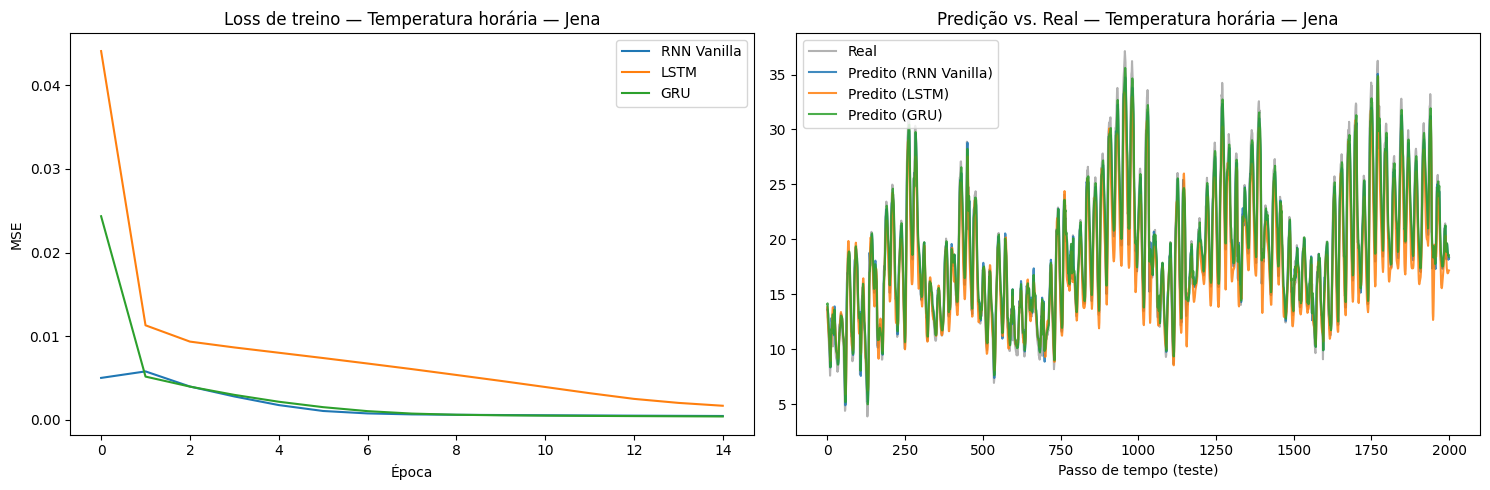

,Modelo,RMSE,MAE
0,RNN Vanilla,1.330433,0.997618
1,GRU,1.344361,1.036857
2,LSTM,2.274856,1.773819


In [ ]:
plot_comparison(jena_results, title="Temperatura horária — Jena")
summary_table(jena_results)


**Pergunta 3.1** — A temperatura tem um padrão diário bem definido (mais quente de dia, mais fria à noite). Dada a janela de 24 horas usada, você esperaria que o modelo capture esse padrão com facilidade? Por quê?

---

**Resposta esperada:**

Sim — uma janela de 24 horas cobre exatamente um ciclo diário completo, então o modelo tem acesso direto à informação necessária para aprender a sazonalidade diária (ex.: "está subindo porque é de manhã"). Esse é um exemplo de por que o tamanho da janela deve refletir a escala temporal do padrão que se quer capturar — uma janela muito mais curta (ex.: 3 horas) perderia a referência ao ciclo completo.

**Pergunta 3.2** — Diferente dos dois estudos de caso anteriores, aqui usamos um `JENA_TRAIN_LIMIT` para reduzir o número de janelas de treino. Que efeito isso provavelmente tem na comparação entre as três arquiteturas, e como você investigaria se a conclusão muda com o dataset completo?

---

**Resposta esperada:**

Com menos dados de treino, modelos mais simples (RNN Vanilla) tendem a ficar relativamente mais competitivos, já que LSTM/GRU têm mais parâmetros e geralmente precisam de mais exemplos para explorar sua capacidade extra. Para investigar, bastaria aumentar `JENA_TRAIN_LIMIT` (ou removê-lo) — idealmente em um ambiente com GPU — e comparar se o ranking de RMSE entre as três arquiteturas se mantém.

## 5. Comparação Final entre os Três Estudos de Caso

**TODO**: monte uma tabela única juntando os resultados dos três estudos de caso (uma linha por
combinação dataset × arquitetura, com o RMSE de cada uma). Dica: use `summary_table(...)` em cada
dicionário de resultados e concatene os `DataFrame`s, adicionando uma coluna `"Dataset"`.


In [ ]:
all_results = {
    "Ações (MA)": stock_results,
    "COVID-19 (Brasil)": covid_results,
    "Temperatura (Jena)": jena_results,
}

tables = []
for dataset_name, results in all_results.items():
    t = summary_table(results)
    t.insert(0, "Dataset", dataset_name)
    tables.append(t)

final_comparison = pd.concat(tables, ignore_index=True)
final_comparison


,Dataset,Modelo,RMSE,MAE
0,Ações (MA),GRU,7.090170,5.580391
1,Ações (MA),RNN Vanilla,7.851599,6.227722
2,Ações (MA),LSTM,8.721171,6.991242
3,COVID-19 (Brasil),GRU,22386.185547,15757.607422
4,COVID-19 (Brasil),LSTM,23318.615234,15217.251953
5,COVID-19 (Brasil),RNN Vanilla,27958.146484,17613.541016
6,Temperatura (Jena),RNN Vanilla,1.330433,0.997618
7,Temperatura (Jena),GRU,1.344361,1.036857
8,Temperatura (Jena),LSTM,2.274856,1.773819


**Pergunta final** — Olhando a tabela consolidada: em qual(is) dataset(s) a diferença entre RNN Vanilla, LSTM e GRU foi maior, e em qual(is) foi menor? O que isso sugere sobre quando vale a pena pagar o custo extra de uma LSTM/GRU em vez de uma RNN simples?

---

**Resposta esperada:**

A diferença tende a ser menor em séries mais curtas/estacionárias (como os casos de ações, com janela relativamente curta) e maior onde há mais dados de treino e dependências de prazo mais longo a capturar (como a temperatura, com um ciclo diário completo de 24 passos). Isso sugere a regra prática: o ganho de LSTM/GRU sobre a RNN Vanilla cresce com (a) o comprimento/complexidade das dependências temporais e (b) a quantidade de dados disponível para explorar a capacidade extra desses modelos — em problemas pequenos e simples, a RNN Vanilla pode não valer muito menos o custo computacional extra de LSTM/GRU.

## 6. Encerramento

Você implementou e comparou RNN Vanilla, LSTM e GRU em três domínios diferentes — finanças, saúde pública e
clima — usando sempre o mesmo pipeline (`create_dataset` → tensor 3D → `DataLoader` → modelo → `train_model`
→ `evaluate_model`). A arquitetura muda; o pipeline ao redor dela, não.
